# Reto avanzado 1: comparativa de algoritmos de clustering

Se compara el K-Means del reto 3 con otros algoritmos, **con el mismo k y los mismos datos preparados**:

| Algoritmo | Idea | Escala |
|---|---|---|
| **K-Means** (referencia) | Centroides; clústeres esféricos | Todos los clientes |
| **MiniBatch K-Means** | K-Means por lotes | Todos los clientes |
| **Gaussian Mixture (GMM)** | Mezcla de gaussianas con covarianza completa; clústeres elípticos y asignación probabilística | Todos los clientes |
| **Birch** | Árbol de características + clustering global | Todos los clientes |
| **Aglomerativo (Ward)** | Jerárquico; une los grupos que menos aumentan la varianza | Muestra de 15.000 (memoria O(n²)) |

**DBSCAN** no está en la tabla porque no acepta un k fijo: el número de clústeres sale de `eps` y `min_samples`. Se
prueba al final para justificar por qué no encaja con estos datos.

Para comparar en igualdad, **todas las métricas se calculan sobre la misma muestra de 15.000 clientes**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Especificaciones_proyecto.md").exists())
PROC = ROOT / "data" / "processed"
FIG = ROOT / "modelo" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE = CAT[0]
DIV = ["#e34948", "#f0efec", "#2a78d6"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 110,
})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def show_md(text):
    display(Markdown(text))

In [2]:
import time

from sklearn.cluster import DBSCAN, AgglomerativeClustering, Birch, KMeans, MiniBatchKMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.mixture import GaussianMixture

X = pd.read_csv(PROC / "features_modelo.csv", dtype={"client_id": str}).set_index("client_id")
ref = pd.read_csv(PROC / "segmentos_kmeans.csv", dtype={"client_id": str}).set_index("client_id").cluster.reindex(X.index)
K = int(ref.nunique())
rng = np.random.default_rng(SEED)
idx = rng.choice(len(X), size=15_000, replace=False)
Xs = X.iloc[idx]
print(f"k = {K} · clientes = {len(X):,} · muestra de evaluación = {len(Xs):,}")

k = 8 · clientes = 172,623 · muestra de evaluación = 15,000


## 1. Entrenamiento

In [3]:
resultados = {}
tiempos = {}


def run(nombre, fn):
    t0 = time.perf_counter()
    resultados[nombre] = fn()
    tiempos[nombre] = time.perf_counter() - t0


run("K-Means", lambda: ref.to_numpy())
run("MiniBatch K-Means", lambda: MiniBatchKMeans(n_clusters=K, random_state=SEED, n_init=10, batch_size=4096).fit_predict(X))
gmm = GaussianMixture(n_components=K, covariance_type="full", random_state=SEED, n_init=2, max_iter=300)
run("Gaussian Mixture", lambda: gmm.fit(X).predict(X))
run("Birch", lambda: Birch(n_clusters=K, threshold=0.8).fit_predict(X))
aglo_s = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Xs)
tiempos["Aglomerativo (Ward)"] = np.nan
print({k: f"{v:.1f} s" for k, v in tiempos.items() if not np.isnan(v)})

{'K-Means': '0.0 s', 'MiniBatch K-Means': '0.4 s', 'Gaussian Mixture': '8.9 s', 'Birch': '59.5 s'}


## 2. Métricas sobre la muestra común

In [4]:
sample_labels = {n: l[idx] for n, l in resultados.items()}
sample_labels["Aglomerativo (Ward)"] = aglo_s
filas = []
for n, l in sample_labels.items():
    filas.append({"algoritmo": n,
                  "silhouette": silhouette_score(Xs, l),
                  "davies_bouldin": davies_bouldin_score(Xs, l),
                  "calinski_harabasz": calinski_harabasz_score(Xs, l),
                  "ARI vs K-Means": adjusted_rand_score(sample_labels["K-Means"], l),
                  "NMI vs K-Means": normalized_mutual_info_score(sample_labels["K-Means"], l),
                  "clúster más pequeño %": np.bincount(l).min() / len(l) * 100})
comp = pd.DataFrame(filas).set_index("algoritmo").sort_values("silhouette", ascending=False)
comp.to_csv(PROC / "comparativa_algoritmos.csv")
comp

,silhouette,davies_bouldin,calinski_harabasz,ARI vs K-Means,NMI vs K-Means,clúster más pequeño %
algoritmo,,,,,,
K-Means,0.163,1.740,"1,650.536",1.000,1.000,4.053
Aglomerativo (Ward),0.155,1.764,"1,478.699",0.528,0.697,4.047
Gaussian Mixture,0.151,2.449,"1,191.432",0.470,0.610,1.200
MiniBatch K-Means,0.145,2.109,"1,415.439",0.494,0.607,4.353
Birch,0.122,2.207,"1,120.300",0.377,0.603,3.267


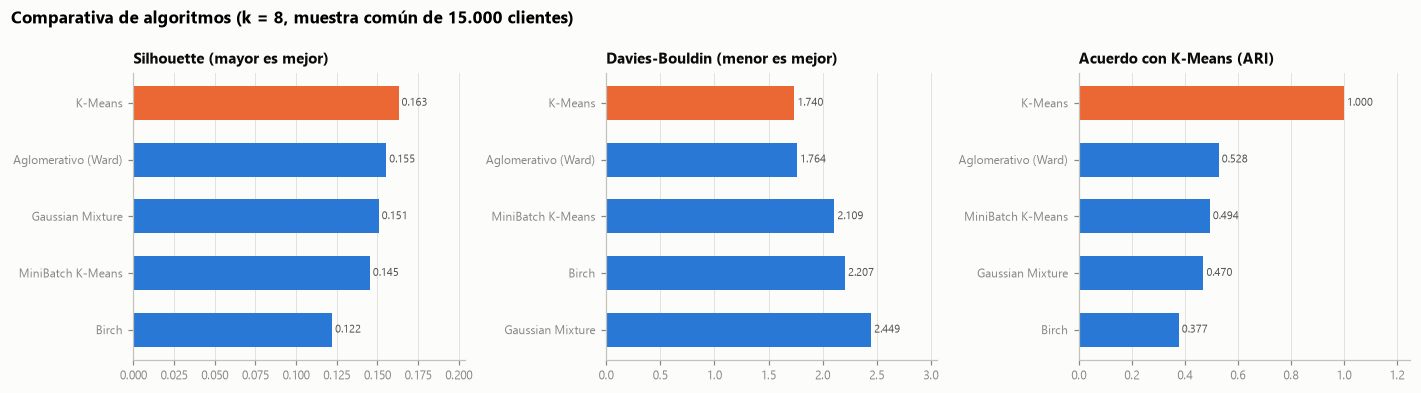

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (col, titulo, mejor) in zip(axes, [("silhouette", "Silhouette (mayor es mejor)", "max"),
                                          ("davies_bouldin", "Davies-Bouldin (menor es mejor)", "min"),
                                          ("ARI vs K-Means", "Acuerdo con K-Means (ARI)", "max")]):
    s = comp[col].sort_values(ascending=(mejor == "min"))[::-1]
    colors = [CAT[1] if n == "K-Means" else BLUE for n in s.index]
    ax.barh(s.index, s.values, height=0.6, color=colors)
    for i, v in enumerate(s.values):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=7.5, color=INK2)
    ax.set_title(titulo, fontsize=10); ax.grid(axis="y", visible=False)
    ax.set_xlim(min(0, s.min() * 1.1), s.max() * 1.25)
fig.suptitle(f"Comparativa de algoritmos (k = {K}, muestra común de 15.000 clientes)", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
save(fig, "a1_comparativa_metricas.png")

## 3. ¿Cambian los segmentos entre algoritmos?

Tablas de contingencia de cada algoritmo frente a K-Means, sobre la muestra y en % de cada clúster de K-Means.
Una fila concentrada en una sola columna indica que ese segmento se reproduce igual.

In [6]:
for n in ["Gaussian Mixture", "Aglomerativo (Ward)", "Birch"]:
    ct = pd.crosstab(pd.Series(sample_labels["K-Means"], name="K-Means"), pd.Series(sample_labels[n], name=n),
                     normalize="index") * 100
    show_md(f"**K-Means (filas) frente a {n} (columnas), % de fila**")
    display(ct.round(1))

**K-Means (filas) frente a Gaussian Mixture (columnas), % de fila**

Gaussian Mixture,0,1,2,3,4,5,6,7
K-Means,,,,,,,,
0,59.300,0.000,8.200,23.300,3.700,3.900,0.100,1.600
1,62.000,0.500,2.600,28.800,3.100,1.500,0.000,1.500
2,98.900,0.000,0.300,0.000,0.600,0.300,0.000,0.000
3,0.000,90.600,0.000,0.000,8.100,0.000,0.000,1.300
4,0.000,0.000,0.000,0.000,4.400,0.000,95.600,0.000
5,4.300,0.600,0.000,92.800,0.400,1.500,0.000,0.400
6,0.000,18.100,40.700,35.800,0.700,3.100,0.000,1.600
7,0.000,0.000,0.000,0.000,3.000,0.000,0.000,97.000


**K-Means (filas) frente a Aglomerativo (Ward) (columnas), % de fila**

Aglomerativo (Ward),0,1,2,3,4,5,6,7
K-Means,,,,,,,,
0,0.000,8.700,0.000,0.000,0.100,88.700,0.000,2.400
1,70.400,0.000,26.900,0.500,0.000,0.100,2.100,0.000
2,79.700,0.000,0.000,0.000,0.000,0.000,20.300,0.000
3,10.200,0.300,0.100,67.200,0.000,0.000,22.300,0.100
4,8.900,0.000,0.000,0.400,90.700,0.000,0.000,0.000
5,4.400,0.400,88.200,0.900,0.000,1.800,4.300,0.000
6,4.500,94.300,0.100,1.000,0.000,0.000,0.000,0.200
7,5.800,0.000,0.000,0.000,0.000,0.000,0.000,94.200


**K-Means (filas) frente a Birch (columnas), % de fila**

Birch,0,1,2,3,4,5,6,7
K-Means,,,,,,,,
0,0.000,0.000,96.700,0.000,2.700,0.600,0.000,0.000
1,87.000,4.100,0.100,0.300,0.000,0.000,7.600,0.800
2,85.100,0.500,0.000,0.100,0.000,0.000,14.200,0.000
3,21.600,8.000,0.000,0.000,0.100,0.000,6.900,63.400
4,0.300,8.300,0.000,0.000,0.000,90.500,0.600,0.300
5,59.600,0.700,1.800,0.400,0.000,0.000,10.300,27.300
6,0.600,2.000,6.900,88.800,0.300,0.000,0.300,1.100
7,0.000,6.100,0.000,0.000,93.900,0.000,0.000,0.000


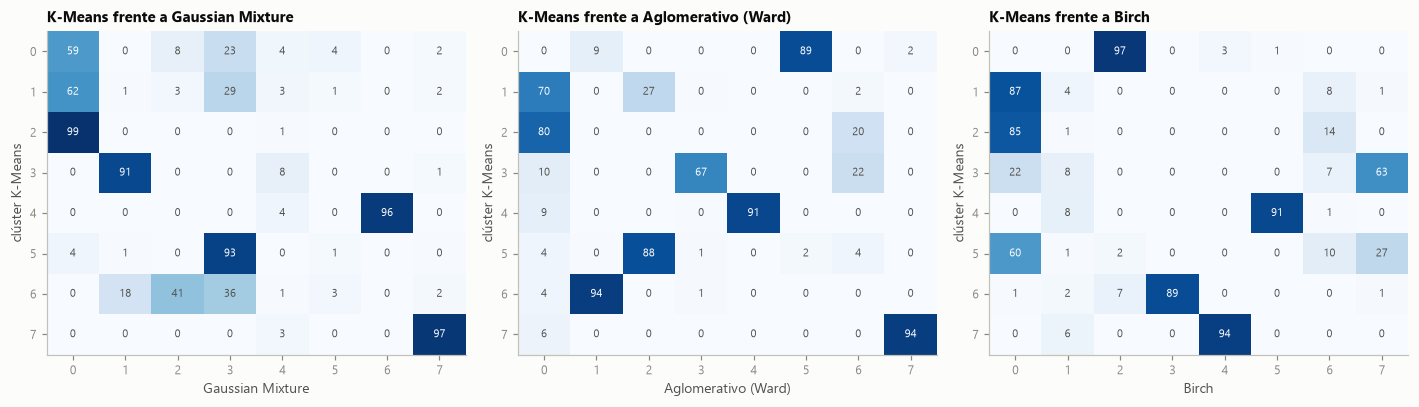

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, n in zip(axes, ["Gaussian Mixture", "Aglomerativo (Ward)", "Birch"]):
    ct = pd.crosstab(sample_labels["K-Means"], sample_labels[n], normalize="index") * 100
    ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(ct.shape[1])); ax.set_yticks(range(ct.shape[0]))
    ax.set_xlabel(n); ax.set_ylabel("clúster K-Means"); ax.grid(False)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax.text(j, i, f"{ct.values[i, j]:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if ct.values[i, j] > 55 else INK2)
    ax.set_title(f"K-Means frente a {n}", fontsize=10)
save(fig, "a1_contingencias.png")

## 4. DBSCAN: por qué no encaja

DBSCAN agrupa por densidad. Se prueba sobre la muestra con varios `eps` (con `min_samples` = 2 × nº de features)
y se mide cuántos clústeres salen y qué parte de los clientes queda como ruido.

In [8]:
dbs = []
for eps in [1.0, 1.5, 2.0, 2.5, 3.0]:
    l = DBSCAN(eps=eps, min_samples=2 * X.shape[1]).fit_predict(Xs)
    n_cl = len(set(l)) - (1 if -1 in l else 0)
    mask = l != -1
    dbs.append({"eps": eps, "clústeres": n_cl, "% ruido": (~mask).mean() * 100,
                "% en el mayor clúster": (np.bincount(l[mask]).max() / len(l) * 100) if mask.any() else 0,
                "silhouette (sin ruido)": silhouette_score(Xs[mask], l[mask]) if n_cl > 1 else np.nan})
pd.DataFrame(dbs).set_index("eps")

,clústeres,% ruido,% en el mayor clúster,silhouette (sin ruido)
eps,,,,
1.000,18,55.120,13.280,0.252
1.500,28,21.260,15.260,0.207
2.000,21,8.120,47.780,0.042
2.500,5,2.273,84.673,0.089
3.000,1,0.160,99.840,NaN


In [9]:
mejor = comp.silhouette.idxmax()
show_md(f"""## 5. Conclusión

- **Silhouette:** el mejor es {mejor} ({comp.loc[mejor, 'silhouette']:.3f}). K-Means obtiene {comp.loc['K-Means', 'silhouette']:.3f},
  MiniBatch {comp.loc['MiniBatch K-Means', 'silhouette']:.3f}, GMM {comp.loc['Gaussian Mixture', 'silhouette']:.3f},
  Ward {comp.loc['Aglomerativo (Ward)', 'silhouette']:.3f} y Birch {comp.loc['Birch', 'silhouette']:.3f}.
- **Acuerdo con K-Means (ARI):** GMM {comp.loc['Gaussian Mixture', 'ARI vs K-Means']:.2f} · Ward {comp.loc['Aglomerativo (Ward)', 'ARI vs K-Means']:.2f} · Birch {comp.loc['Birch', 'ARI vs K-Means']:.2f} · MiniBatch {comp.loc['MiniBatch K-Means', 'ARI vs K-Means']:.2f}.
  Un ARI alto indica que los segmentos son sobre todo una estructura real de los datos y no un artefacto del algoritmo.
- **GMM** permite clústeres elípticos y da probabilidades de pertenencia, pero sus segmentos son más difíciles de explicar
  (covarianzas completas) y su silhouette es {"mejor" if comp.loc['Gaussian Mixture', 'silhouette'] > comp.loc['K-Means', 'silhouette'] else "peor"} que el de K-Means.
- **Ward** solo es viable sobre una muestra: no puede segmentar los 172.000 clientes ni asignar clientes nuevos sin un clasificador adicional.
- **DBSCAN** no encaja: con `eps` pequeño deja más de la mitad de los clientes como ruido y genera decenas de microclústeres,
  y con `eps` grande agrupa al 85–100 % en un único clúster. Las variables binarias y las proporciones crean "rejillas" de densidad
  que no corresponden a segmentos de negocio.
- **Cambios entre algoritmos:** furgonetas, élite eléctrica/lujo y Familia SUV se reproducen en GMM y en Ward con un 88–97 % de
  coincidencia; Ward también reproduce ex-clientes y AMG, mientras que GMM reparte AMG entre varios componentes. Las diferencias se
  concentran en la frontera entre Berlina clásica, Compacto al contado y Ex-cliente (GMM y Ward fusionan casi por completo Berlina
  clásica y Compacto al contado), la misma zona que el reto avanzado 3 identifica como la menos estable.

**Recomendación:** mantener **K-Means**. Combina la mejor o casi la mejor calidad interna, escala a toda la base, asigna clientes nuevos al
centroide más cercano y produce centroides fáciles de explicar a marketing. MiniBatch K-Means sería la alternativa si la base crece
mucho, pero su acuerdo con K-Means es moderado (ARI {comp.loc['MiniBatch K-Means', 'ARI vs K-Means']:.2f}): habría que revalidar los segmentos.""")

## 5. Conclusión

- **Silhouette:** el mejor es K-Means (0.163). K-Means obtiene 0.163,
  MiniBatch 0.145, GMM 0.151,
  Ward 0.155 y Birch 0.122.
- **Acuerdo con K-Means (ARI):** GMM 0.47 · Ward 0.53 · Birch 0.38 · MiniBatch 0.49.
  Un ARI alto indica que los segmentos son sobre todo una estructura real de los datos y no un artefacto del algoritmo.
- **GMM** permite clústeres elípticos y da probabilidades de pertenencia, pero sus segmentos son más difíciles de explicar
  (covarianzas completas) y su silhouette es peor que el de K-Means.
- **Ward** solo es viable sobre una muestra: no puede segmentar los 172.000 clientes ni asignar clientes nuevos sin un clasificador adicional.
- **DBSCAN** no encaja: con `eps` pequeño deja más de la mitad de los clientes como ruido y genera decenas de microclústeres,
  y con `eps` grande agrupa al 85–100 % en un único clúster. Las variables binarias y las proporciones crean "rejillas" de densidad
  que no corresponden a segmentos de negocio.
- **Cambios entre algoritmos:** furgonetas, élite eléctrica/lujo y Familia SUV se reproducen en GMM y en Ward con un 88–97 % de
  coincidencia; Ward también reproduce ex-clientes y AMG, mientras que GMM reparte AMG entre varios componentes. Las diferencias se
  concentran en la frontera entre Berlina clásica, Compacto al contado y Ex-cliente (GMM y Ward fusionan casi por completo Berlina
  clásica y Compacto al contado), la misma zona que el reto avanzado 3 identifica como la menos estable.

**Recomendación:** mantener **K-Means**. Combina la mejor o casi la mejor calidad interna, escala a toda la base, asigna clientes nuevos al
centroide más cercano y produce centroides fáciles de explicar a marketing. MiniBatch K-Means sería la alternativa si la base crece
mucho, pero su acuerdo con K-Means es moderado (ARI 0.49): habría que revalidar los segmentos.